# GPT from Scratch
### Character-level language modelling, architectural ablations, and sampling

**Lukas Blömer** · PyTorch · Tiny Shakespeare

How much can a small Transformer learn from next-character prediction, and what changes
when I remove positional embeddings or change the decoding strategy?

This project brings together a bigram baseline, two GPT sizes, an ablation without learned
positional embeddings, and temperature, top-k, and nucleus sampling. I use training curves,
generated dialogue, and attention maps to connect implementation choices to measured behaviour.

The starting implementation follows Andrej Karpathy's
[GPT lecture](https://www.youtube.com/watch?v=kCc8FmEb1nY) and
[nanoGPT](https://github.com/karpathy/nanoGPT).

**Explore:** [Results at a glance](#results) · [Full-size GPT](#full-run) ·
[Positional embeddings](#positions) · [Sampling](#sampling) · [Attention](#attention) ·
[Implementation](#implementation) · [Run your own experiments](#rerun) · [Credits](#credits)

<a id="results"></a>
## 1. Results at a glance

All losses are next-character cross-entropy in **nats** on a chronological 10% validation
split. Lower is better. Character-level perplexity is `exp(loss)`; it is only comparable
here because every run uses the same 65-character vocabulary and corpus split.

| Recorded run | Parameters | Steps | Final train | Final validation | Best validation (step) | Final perplexity |
|---|---:|---:|---:|---:|---:|---:|
| Bigram baseline | 4,225 | 3,000 | 2.4561 | 2.4842 | 2.4842 (3,000) | 11.99 |
| GPT · full | 10,788,929 | 5,000 | 0.8510 | 1.5810 | 1.4903 (3,000) | 4.86 |
| GPT · fast baseline | 824,897 | 3,000 | 1.3895 | 1.5829 | 1.5829 (3,000) | 4.87 |
| GPT · no positions | 808,513 | 3,000 | 1.6231 | 1.7912 | 1.7912 (3,000) | 6.00 |
| GPT · sampling run | 824,897 | 3,000 | 1.3905 | 1.5803 | 1.5803 (3,000) | 4.86 |

Three findings stand out:

- **Context matters:** the full GPT finishes at **1.5810** validation loss versus **2.4842**
  for the bigram baseline. Its best recorded checkpoint is earlier, at **1.4903**.
- **Learned positions help in this run:** removing them raises validation loss from
  **1.5829 to 1.7912** under the same fast preset, a difference of **0.2083 nats**.
- **Decoding changes the style:** temperature and nucleus filtering change repetition
  and word formation, but they cannot repair the model's limited language modelling.

The two fast GPT runs are separate recorded experiments: the **fast baseline** belongs
to the positional ablation, while the **sampling run** supplies the top-p examples.
Their slightly different results are kept separate. The full preset also changes context
length, dropout, learning rate, batch size, and training duration, so it is not a size-only comparison.

In [ ]:
import math
import re
from pathlib import Path
from dataclasses import dataclass, asdict
import time
import urllib.request

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [ ]:
# Histories transcribed from saved logs; values are rounded to four decimal places.
saved_histories = {'bigram': [(0, 4.7529, 4.7573),
            (500, 2.5172, 2.5432),
            (1000, 2.474, 2.498),
            (1500, 2.4639, 2.4895),
            (2000, 2.4594, 2.4888),
            (2500, 2.4565, 2.4854),
            (3000, 2.4561, 2.4842)],
 'full': [(0, 4.2216, 4.2311),
          (500, 1.7443, 1.8978),
          (1000, 1.3892, 1.6103),
          (1500, 1.2667, 1.5331),
          (2000, 1.1881, 1.5108),
          (2500, 1.1205, 1.4965),
          (3000, 1.0648, 1.4903),
          (3500, 1.0157, 1.5002),
          (4000, 0.9549, 1.5136),
          (4500, 0.9035, 1.5566),
          (5000, 0.851, 1.581)],
 'fast': [(0, 4.134, 4.1332),
          (500, 1.8454, 1.9666),
          (1000, 1.6004, 1.7794),
          (1500, 1.5013, 1.697),
          (2000, 1.454, 1.656),
          (2500, 1.411, 1.616),
          (3000, 1.3895, 1.5829)],
 'no_position': [(0, 4.1526, 4.1533),
                 (500, 2.2617, 2.3295),
                 (1000, 1.9399, 2.0574),
                 (1500, 1.7777, 1.9328),
                 (2000, 1.6964, 1.8636),
                 (2500, 1.6515, 1.8295),
                 (3000, 1.6231, 1.7912)],
 'sampling': [(0, 4.134, 4.1332),
              (500, 1.8467, 1.9624),
              (1000, 1.6004, 1.7666),
              (1500, 1.5065, 1.6999),
              (2000, 1.4547, 1.6567),
              (2500, 1.4149, 1.6206),
              (3000, 1.3905, 1.5803)]}

# Keep archival measurements separate from any new training runs.
live_runs = {}

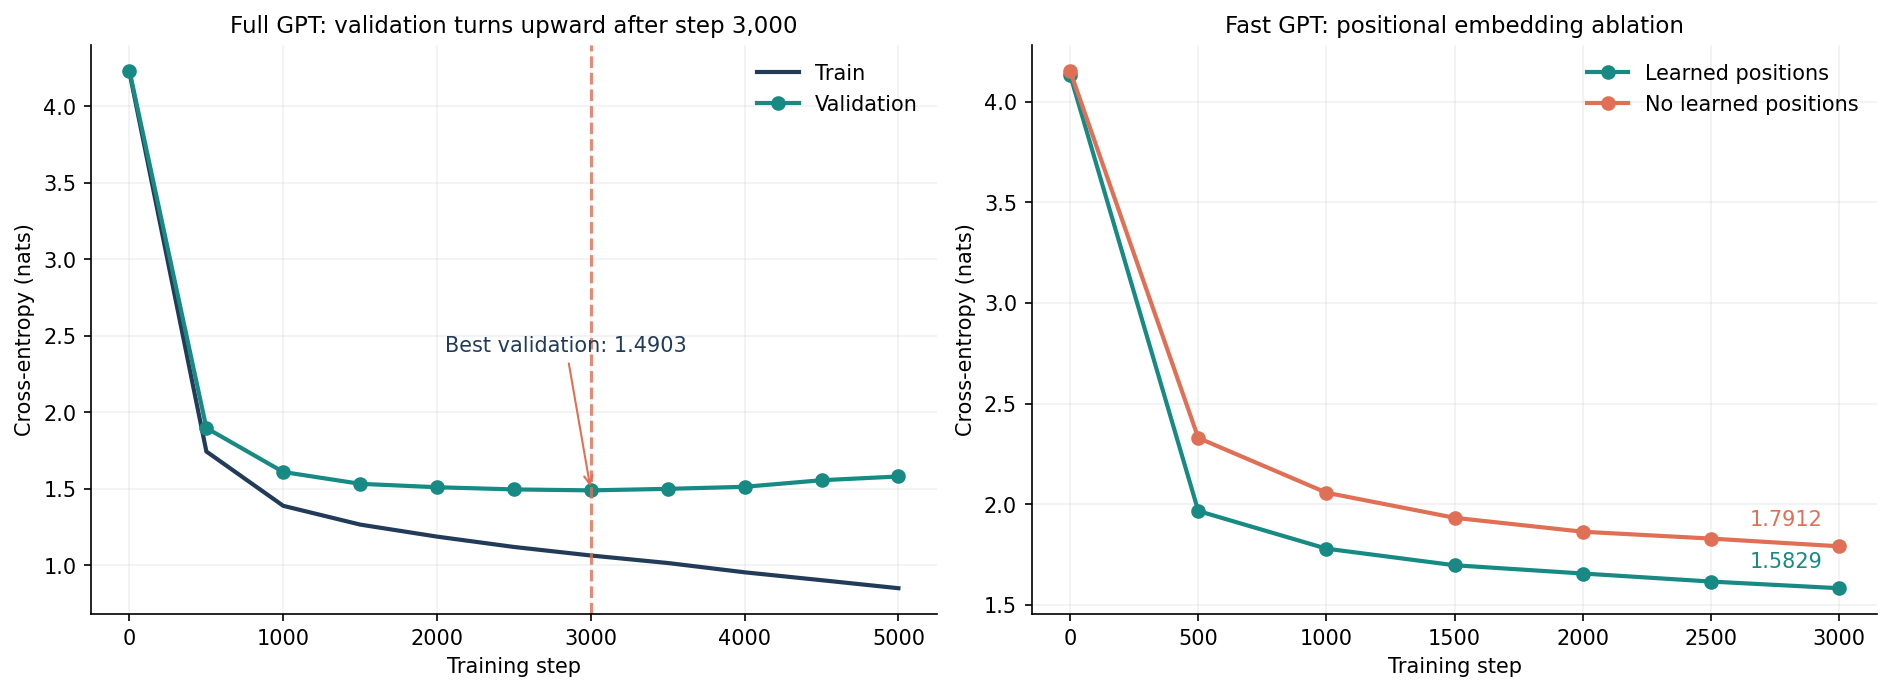

In [ ]:
def plot_comparison(histories):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), constrained_layout=True)
    navy, teal, coral = '#223b59', '#168a83', '#df7056'
    full = histories['full']
    steps, train_loss, val_loss = zip(*full)
    axes[0].plot(steps, train_loss, color=navy, label='Train', linewidth=2)
    axes[0].plot(steps, val_loss, color=teal, marker='o', label='Validation', linewidth=2)
    best = min(full, key=lambda row: row[2])
    axes[0].axvline(best[0], color=coral, linestyle='--', alpha=0.8)
    axes[0].annotate(f'Best validation: {best[2]:.4f}', xy=(best[0], best[2]),
                     xytext=(2050, 2.4), arrowprops={'arrowstyle': '->', 'color': coral},
                     fontsize=10, color=navy)
    axes[0].set_title('Full GPT: validation turns upward after step 3,000', fontsize=11)
    for key, label, color in [('fast', 'Learned positions', teal),
                              ('no_position', 'No learned positions', coral)]:
        steps, _, val_loss = zip(*histories[key])
        axes[1].plot(steps, val_loss, marker='o', color=color, label=label, linewidth=2)
        axes[1].annotate(f'{val_loss[-1]:.4f}', (steps[-1], val_loss[-1]),
                         xytext=(-8, 10), textcoords='offset points', ha='right', color=color)
    axes[1].set_title('Fast GPT: positional embedding ablation', fontsize=11)
    for ax in axes:
        ax.set(xlabel='Training step', ylabel='Cross-entropy (nats)')
        ax.grid(alpha=0.18)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(frameon=False)
    plt.show()

plot_comparison(saved_histories)

### Data and experimental setup

The Tiny Shakespeare corpus contains **1,115,394 characters**, mapped to **65 token IDs**.
I use the first **1,003,854 tokens** for training and the remaining **111,540** for validation.
Each batch pairs a context window with the same text shifted one character to the right.
Every position predicts its next character, and a causal mask prevents access to future tokens.

| Setting | Fast preset | Full preset |
|---|---:|---:|
| Batch size | 32 | 64 |
| Context length | 128 | 256 |
| Embedding width | 128 | 384 |
| Attention heads | 4 | 6 |
| Transformer blocks | 4 | 6 |
| Dropout | 0.1 | 0.2 |
| AdamW learning rate | 0.001 | 0.0003 |
| Updates | 3,000 | 5,000 |
| Evaluation | 100 batches per split, every 500 updates | Same |

The original runs used **PyTorch 2.11.0+cu130 on CUDA** and seed **1337**.
The fast ablation runs reset the seed before model creation and again before training.
Removing an embedding table also changes subsequent random initialisation, so this is
a comparison of the recorded runs rather than a guarantee of identical random weights.
One seed and one validation split support a useful observation, not a universal claim.

<a id="full-run"></a>
## 2. From a bigram baseline to a full GPT

A bigram model predicts the next character from the current character alone using a
`65 × 65` lookup table. It learns common character transitions but cannot condition on a word,
speaker, or sentence. The Transformer adds a context window, causal self-attention, and
position-wise feed-forward layers.

**Preserved bigram training log and sample.** The bigram uses AdamW at `lr=0.01` for 3,000 updates.

```text
step     0 | train loss 4.7529 | val loss 4.7573 |    0.4s
step   500 | train loss 2.5172 | val loss 2.5432 |    2.5s
step  1000 | train loss 2.4740 | val loss 2.4980 |    4.3s
step  1500 | train loss 2.4639 | val loss 2.4895 |    6.2s
step  2000 | train loss 2.4594 | val loss 2.4888 |    8.0s
step  2500 | train loss 2.4565 | val loss 2.4854 |    9.9s
step  3000 | train loss 2.4561 | val loss 2.4842 |   11.8s

--- trained bigram sample ---

BE:
Wileranousel lind me l.
HAshe ce hiry:
Supr aisspllw y.
Herindu n Boopetelaves
MP:

Pl, d mothakleo Windo whthCoribyo the m dourive we hidend t so mower; te

AN ad nterupt f s ar iris! m:

Thiny aleronth,
Mad
RD:

WISo myr f-
LIERor,
SShisar adsal thes ghesthidin cour ay aney Iry ts I fr y ce.
J
```

### Full GPT: learning and then overfitting

With **10,788,929 parameters**, the full model learns far more than character transitions.
Both losses fall initially. Validation reaches its recorded minimum of **1.4903 at step 3,000**,
then rises to **1.5810**, while training loss keeps falling to **0.8510**.
This widening gap is evidence of overfitting in this run. Selecting the best validation
checkpoint would preserve better validation performance than keeping the final checkpoint.

The text samples below come from the **final model**, matching the original experiment;
they are not samples from the best validation checkpoint.

```text
step     0 | train loss 4.2216 | val loss 4.2311 |   30.8s
step   500 | train loss 1.7443 | val loss 1.8978 |  323.7s
step  1000 | train loss 1.3892 | val loss 1.6103 |  616.5s
step  1500 | train loss 1.2667 | val loss 1.5331 |  909.2s
step  2000 | train loss 1.1881 | val loss 1.5108 | 1199.7s
step  2500 | train loss 1.1205 | val loss 1.4965 | 1491.3s
step  3000 | train loss 1.0648 | val loss 1.4903 | 1782.3s
step  3500 | train loss 1.0157 | val loss 1.5002 | 2073.5s
step  4000 | train loss 0.9549 | val loss 1.5136 | 2364.5s
step  4500 | train loss 0.9035 | val loss 1.5566 | 2656.3s
step  5000 | train loss 0.8510 | val loss 1.5810 | 2947.9s
```

In [ ]:
def plot_recorded_run(history, bigram_history, title):
    steps, train_loss, val_loss = zip(*history)
    b_steps, _, b_val = zip(*bigram_history)
    plt.figure(figsize=(7, 4))
    plt.plot(steps, train_loss, marker='o', label='GPT train')
    plt.plot(steps, val_loss, marker='o', label='GPT val')
    plt.plot(b_steps, b_val, linestyle='--', color='gray', label='bigram val')
    plt.xlabel('training step')
    plt.ylabel('cross-entropy loss (nats)')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    print(f'Final validation loss -> bigram: {bigram_history[-1][2]:.3f} | GPT: {history[-1][2]:.3f}')
    print(f'Perplexity (exp of loss) -> bigram: {math.exp(bigram_history[-1][2]):.1f} | GPT: {math.exp(history[-1][2]):.1f}')

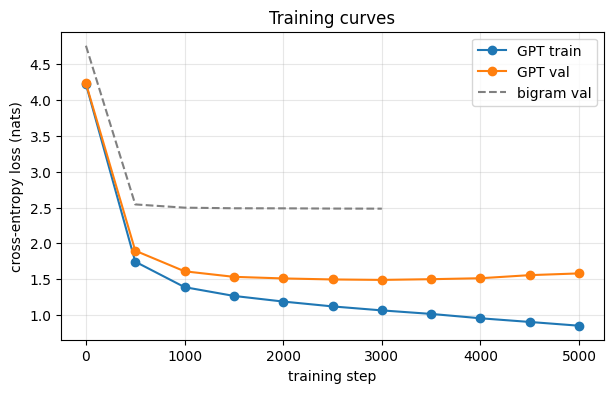

Final validation loss -> bigram: 2.484 | GPT: 1.581
Perplexity (exp of loss) -> bigram: 12.0 | GPT: 4.9


In [ ]:
# Original saved curve; rerunning this cell rebuilds it from the saved logs.
plot_recorded_run(saved_histories['full'], saved_histories['bigram'], 'Training curves')

### A 600-character continuation

Starting from a newline, with sampling seed `0`, temperature `1.0`, and no filtering:

```text

A prayer heavy storic answer you be
And unnatural. Let him be gone.

AUFIDIUS:
You shall not guard then,--'Stay no, no.
They that have made fear'd and very groans
Nothing but they have laugh'd it.

CORIOLANUS:
Very well;
My promise is fill'd to power, my prayers in one,
Now it is more than she will prove to them,
Commit the flowers; but it is amoved?

VOLUMNIA:
Now prithee, sir: when the spirits o' the people,
She is as filt youth of the deep death,
Not so gracious villain.

MARCIUS:
The people, Isabel,
Or else you do not
Undertake the point of your own price.

COMINIUS:
Marcius,
These o'er-mu
```

Speaker labels, line breaks, and many real words emerge from next-character prediction.
Phrases such as “My promise is fill'd to power” look stylistically plausible, but the
dialogue lacks consistent meaning. The model learns local statistical structure;
this experiment does not establish understanding or conversational ability.

### Temperature and top-k on the full model

Each continuation uses the same `ROMEO:\n` prompt, final model, seed `0`, and 250 new characters.
Temperature `0.5` gives the clearest dialogue in these samples. At `1.5`, malformed words
such as “wimother” appear. Top-k `10` removes low-ranked candidates but still permits errors.

```text

==================== temperature=0.5, top_k=None ====================
ROMEO:
Ay, but the very poisoner of my heart,
Which is my name for my presence to the king!

JULIET:
You must not stay the other duke.

ROMEO:
Nay, good soul, be gone.

Nurse:
Lady, that hast thou been breathed to death.

JULIET:
What is the matter?

Nurse:

==================== temperature=1.0, top_k=None ====================
ROMEO:
Put your health in it.

JULIET:
What hast thou then? o, friar?

Nurse:
Ay, an hour ship.

Nurse:
How noW! my manners have straight you a ducat,
Jack should swear death to-night, and idly day
Whiles I did take, or yourselves and lookers,
And none own 

==================== temperature=1.0, top_k=10 ====================
ROMEO:
Ay, but no gentleman born.

LEONTES:
Assista her hundred's rudge,
Devouring her, steward, the blood of her husband,
Her love-storn; the mark hath slipp'd these wounds
Of all the people that which seems to thee!
Thy father, thy blood heart'st to low m

==================== temperature=1.5, top_k=None ====================
ROMEO:
Put your healt and impossibile.
Draw him in: in meddle guard's prayers:
What's this! it will groan, too wimother.
In heavy, man; and leave it stays for either's love;
But by the small old confounds I'll find ye with wrong,
Fanter of myself,' to low y
```

<a id="positions"></a>
## 3. Ablation: remove learned positional embeddings

I removed the positional embedding table and changed the input to the Transformer from
`token_embedding + position_embedding` to `token_embedding`. Causal masking, attention
scaling, layer normalization, residual connections, and the feed-forward layers remain.

Both runs below use the **fast preset**, 3,000 updates, and seed 1337. The companion
fast-baseline experiment is included so this comparison uses matching hyperparameters.

| | Learned positions | No learned positions |
|---|---:|---:|
| Trainable parameters | 824,897 | 808,513 |
| Final training loss | 1.3895 | 1.6231 |
| Final validation loss | 1.5829 | 1.7912 |
| Final perplexity | 4.87 | 6.00 |

The **0.2083-nat** validation gap corresponds to about **23% higher character perplexity**.
Both validation curves are still falling at the end. In this training budget, explicit
positions improve learning. A decoder without position embeddings is still affected by
the causal mask and stacked layers; removing the table does not make it wholly insensitive
to order. This distinction is also discussed by
[Kazemnejad et al. (2023)](https://arxiv.org/abs/2305.19466).

### Recorded fast baseline

```text
step     0 | train loss 4.1340 | val loss 4.1332 |    1.6s
step   500 | train loss 1.8454 | val loss 1.9666 |   16.3s
step  1000 | train loss 1.6004 | val loss 1.7794 |   30.7s
step  1500 | train loss 1.5013 | val loss 1.6970 |   44.8s
step  2000 | train loss 1.4540 | val loss 1.6560 |   59.0s
step  2500 | train loss 1.4110 | val loss 1.6160 |   73.1s
step  3000 | train loss 1.3895 | val loss 1.5829 |   86.9s
```

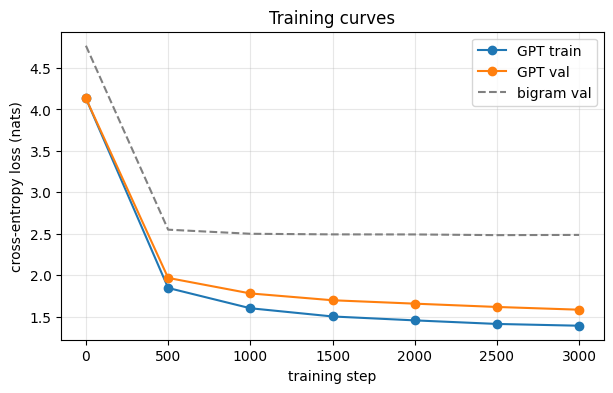

Final validation loss -> bigram: 2.486 | GPT: 1.583
Perplexity (exp of loss) -> bigram: 12.0 | GPT: 4.9


In [ ]:
saved_fast_bigram_history = [(0, 4.7765, 4.7699), (500, 2.5272, 2.5491), (1000, 2.4741, 2.4996), (1500, 2.4625, 2.4923), (2000, 2.4624, 2.4915), (2500, 2.4563, 2.4832), (3000, 2.4588, 2.4859)]
plot_recorded_run(saved_histories['fast'], saved_fast_bigram_history, 'Training curves')

### Recorded model without positional embeddings

```text
step     0 | train loss 4.1526 | val loss 4.1533 |    1.6s
step   500 | train loss 2.2617 | val loss 2.3295 |   15.6s
step  1000 | train loss 1.9399 | val loss 2.0574 |   29.5s
step  1500 | train loss 1.7777 | val loss 1.9328 |   43.4s
step  2000 | train loss 1.6964 | val loss 1.8636 |   57.2s
step  2500 | train loss 1.6515 | val loss 1.8295 |   71.6s
step  3000 | train loss 1.6231 | val loss 1.7912 |   85.7s
```

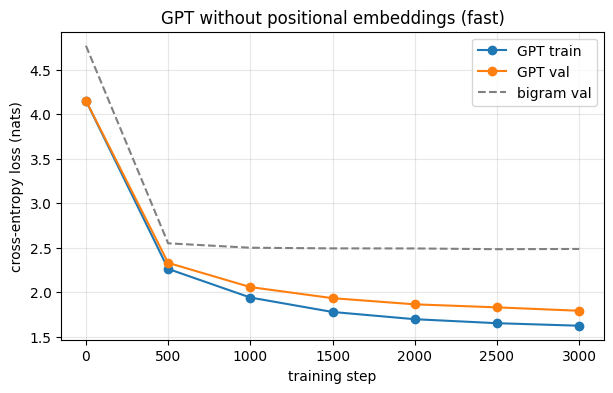

Final validation loss -> bigram: 2.486 | GPT: 1.791
Perplexity (exp of loss) -> bigram: 12.0 | GPT: 6.0


In [ ]:
plot_recorded_run(saved_histories['no_position'], saved_fast_bigram_history,
                  'GPT without positional embeddings (fast)')

### Generated text without learned positions

The final model's 600-character sample (seed `0`) retains dialogue-like formatting,
but contains conspicuous misspellings and repetition. This qualitative observation
is consistent with its higher validation loss.

```text

Puart I no all Clitimen, you you come,
For it well not guess want
Duke to be for stervoiling grace, to Warm the shealf unce!

POLUCENTIO:
Will, and feveriough a gongue to belied am
That but be in seven of theee king with werent
By some, buld that wanchm tabe eeanere, for blehen for my huseld.

LEONTES:
Ay, do can the craison vener Bencariude,
For is by you poinson? pamenty him?

KING RICHARD III:
Who willl it should head; Stay; trun my he been a-
I you from pugget you greave goung thang
Reman Edwarm they preath!
First Lount:
Know, Ithy pring not I had this the he mother!

LONTERS:
He's I one l
```

The same prompt and decoding controls are preserved below. Lowering temperature reduces
randomness but still produces repetitions such as “the the”; decoding alone cannot
compensate for the weaker trained model.

```text

==================== temperature=0.5, top_k=None ====================
ROMEO:
Ay, they heave a mother subject.

QUEEN ELIZABETH:
What would me much in the for the house to brother?
Which he shall be the the father their at heart
counter a the blen and the the canourters in be his for deeath for.

First Gentleman:
And the low n

==================== temperature=1.0, top_k=None ====================
ROMEO:
Puary, but all Clitizens? but comme
this way: well not guess ways
Duke your batt sis it.

MENENIIUS:
Will mat deshen he comme tor ther me of thim.

Second Servargent hencant to pumpond land
Shall be whave theee wis your wrecant
By some, buld to low y

==================== temperature=1.0, top_k=10 ====================
ROMEO:
Ay, a I theee, and the bids,
And you have blods, my lord's son? thu which as why sis hould.

CLARENCE:
Which he sheal but stent a there's of thinks.

First LUCINIUNIUS:
But then that held a be in seven of theee comfortian,
Band those more hims toown:

==================== temperature=1.5, top_k=None ====================
ROMEO:
Puary,
Muceal, Clitime! shumby.

SIA:
Our I? inen. nce, for my GrUpuy in lok' had,
A it unghng, I loke Waim thered,
You commmblorn; Make a is a ahalf heer ups awe
Nakl natumly drumarid law-

VO:
Ay I'll, thudeeou your.

Firspere do Gent beld?


Vown:
```

<a id="sampling"></a>
## 4. Extend decoding with top-p sampling

I added **nucleus (top-p) sampling** to the common generation function. For each next-token
distribution, the algorithm sorts characters by probability and keeps the smallest prefix
whose cumulative probability reaches `p`. It retains the character that crosses the threshold,
restores vocabulary order, and renormalises before drawing a sample.
Unlike top-k, its candidate count varies with the distribution. See
[Holtzman et al. (2020)](https://arxiv.org/abs/1904.09751).

| Control | What changes | Values compared |
|---|---|---|
| Temperature | Scale logits before softmax | 0.5, 1.0, 1.5 |
| Top-k | Retain the highest-ranked characters | 10 |
| Top-p | Retain a probability-mass nucleus | 0.80, 0.90, 0.95 |

The sampling experiment uses a separate fast-model run. Every comparison below uses its
**same final checkpoint**, prompt `ROMEO:\n`, 250 new characters, and a seed reset to **1337**.
This seed differs from the full-model samples, so comparisons are made within each experiment.

```text
step     0 | train loss 4.1340 | val loss 4.1332 |    1.6s
step   500 | train loss 1.8467 | val loss 1.9624 |   15.4s
step  1000 | train loss 1.6004 | val loss 1.7666 |   28.9s
step  1500 | train loss 1.5065 | val loss 1.6999 |   42.5s
step  2000 | train loss 1.4547 | val loss 1.6567 |   56.0s
step  2500 | train loss 1.4149 | val loss 1.6206 |   69.5s
step  3000 | train loss 1.3905 | val loss 1.5803 |   83.3s
```

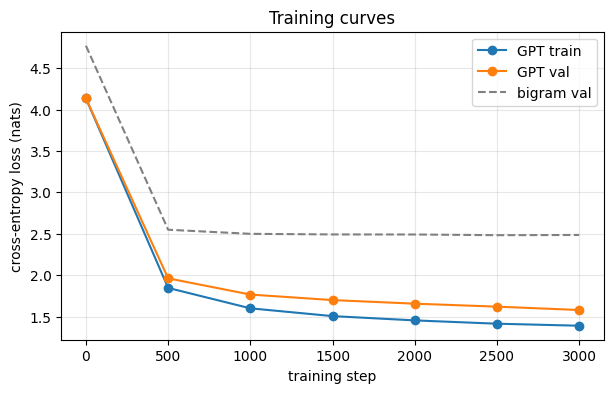

Final validation loss -> bigram: 2.486 | GPT: 1.580
Perplexity (exp of loss) -> bigram: 12.0 | GPT: 4.9


In [ ]:
plot_recorded_run(saved_histories['sampling'], saved_fast_bigram_history, 'Training curves')

### A standard continuation from the sampling model (newline prompt, seed 0)

```text

Put you? heaven thou art you were?

ABHORSON:
Fellow; I for my proud.

ANGELO:
You shall not grace their impure shall buckit there;
And making, and be very great death to believe
mercy law and in seven very deeds your true;
Ender-seeming much calous for tabs envy,
And bleemento to made I have it out to-morrow;

Get lords:
My voice, my lord, blomiself?

GLOUCESTER:
His woman, Margaret, serves best thou couldst shouldst?

MOSTANLEY:
Why the bed than death; I give thy man, make go I
not not, for Englime, he presence is once:
the pest it no birtal the more. But Sir Jominify!

LRANIO:
Then you oath
```

### Seven decoding settings on the same trained model

```text

============ Temperature 0.5: temperature=0.5, top_k=None, top_p=None ============
ROMEO:
What the brids will be love to be seek of the way.
Our soul gatest be that thus hath been to had a end.

MENENIUS:
I would not to the to the common of this brief is the neck.

Second Citizen:
He was the house and self and that the heart with a speedi

============ Standard sampling: temperature=1.0, top_k=None, top_p=None ============
ROMEO:
What before we will be lay be madest?
More to take On them?

LUCIO:
You that us hath been to lady, enjoy the confordarit of
my nown proof in her than well my beg is entent, will it therevess,
He will now on that with lind me little much with a cresti

============ Temperature 1.5: temperature=1.5, top_k=None, top_p=None ============
ROMEO:
What? Dare's cowd, Tyrals, but
backet bubecause Stir-a my calaed
he's nothiek'squest. that dilthoat, away, my feans,
You knoughtowns, tof it is covert; dilinceed is ensent,
A latest in ov tears.

WARWIVGDERCY:
O Grels: no mean.
How my childy: but Mar

============ Top-k = 10: temperature=1.0, top_k=10, top_p=None ============
ROMEO:
What before we will be and be madest my be does
Short's cheelinather?' Warwick the heath cretitus,
But when I defy they have heavens
Much in her than well my beg are,--
Become at that move to do;
Where here you see which you have she course speak;
Or

============ Top-p = 0.80: temperature=1.0, top_k=None, top_p=0.8 ============
ROMEO:
What before we will be and be madest my be does
Should strew at our arm that a contrants we that a from that he false
And I make with the way common wherein was my weeds.

CLAUDIO:
Give my son, be me from to warment, like me here,
We come by stay be 

============ Top-p = 0.90: temperature=1.0, top_k=None, top_p=0.9 ============
ROMEO:
What before we will be lay be madest?
To you wear hath my call'd her rant he should to behed?

DUKE VINCENTIO:
What's on you have to much in her than well
What senseless have latest in or the country's proclaim.

LADY GREY:
So this much with preparti

============ Top-p = 0.95: temperature=1.0, top_k=None, top_p=0.95 ============
ROMEO:
What before we will be lay be madest?
More to take and my call'd heaven that us he hand?
Fear thou hast cry you, not prizens he own proof it.
But this nurse, and if ever he will is the or the country's.

WARWICK:
Well in you have shall cribe preparat
```

**What I observed.** Temperature `0.5` produces simpler text but repeats phrases such as
“to the to the”. Temperature `1.5` introduces many malformed words and unusual names.
Top-p `0.80` still repeats words and makes grammatical errors. Top-p `0.90` produces
recognisable labels such as “DUKE VINCENTIO”, but the sentences remain awkward.
Top-p `0.95` also contains errors; more candidates do not clearly improve readability here.

These are qualitative comparisons of individual samples. They show control over the
generation distribution, without establishing that one threshold is consistently best.

<a id="attention"></a>
## 5. Inspecting attention

I recorded attention weights for the prompt `First Citizen:\nBefore we proceed`.
Rows are queries; columns are keys. The empty upper triangle shows that future characters
are masked. The full model's early maps concentrate near the diagonal; later maps distribute
weight across more of the available context. Heads show different patterns.

The images below are **preserved from the original model runs**, not reconstructed from
the training logs. Attention weights indicate where a head assigns weight for this prompt;
they are not a complete explanation of a model's prediction.

### Full GPT: all six layers

**Layer 0 · first four attention heads**

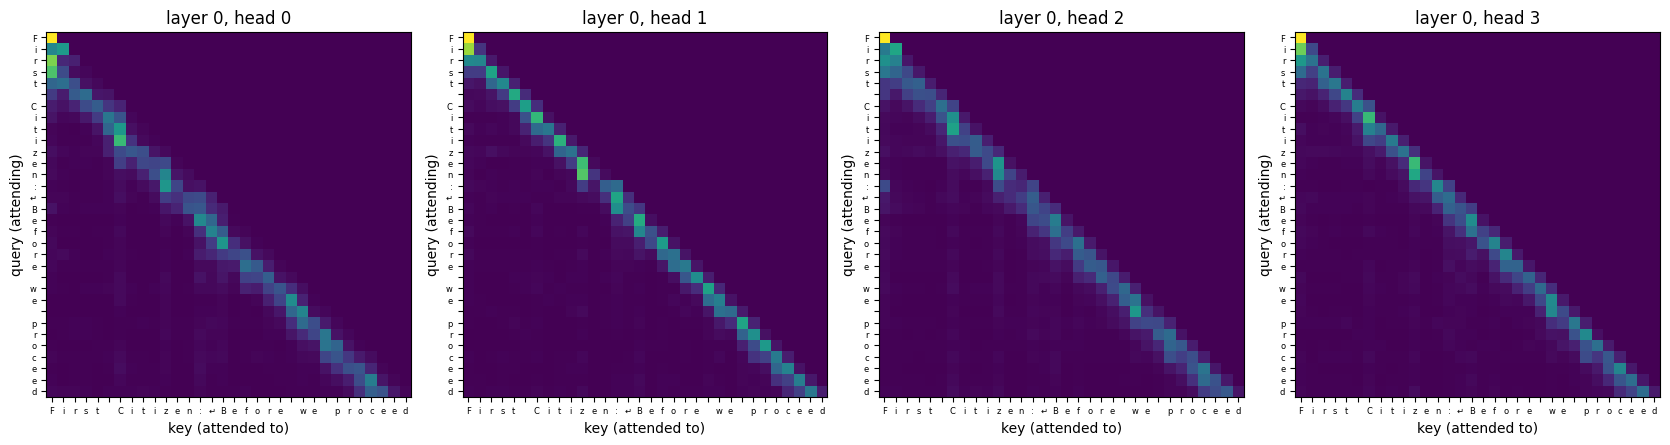

**Layer 1 · first four attention heads**

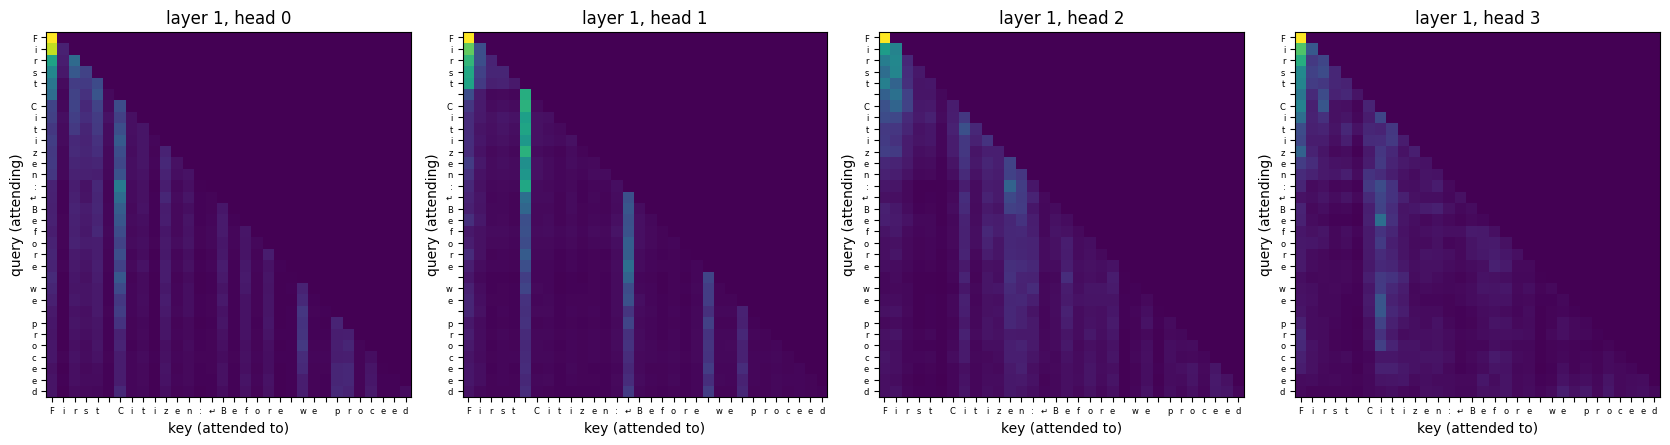

**Layer 2 · first four attention heads**

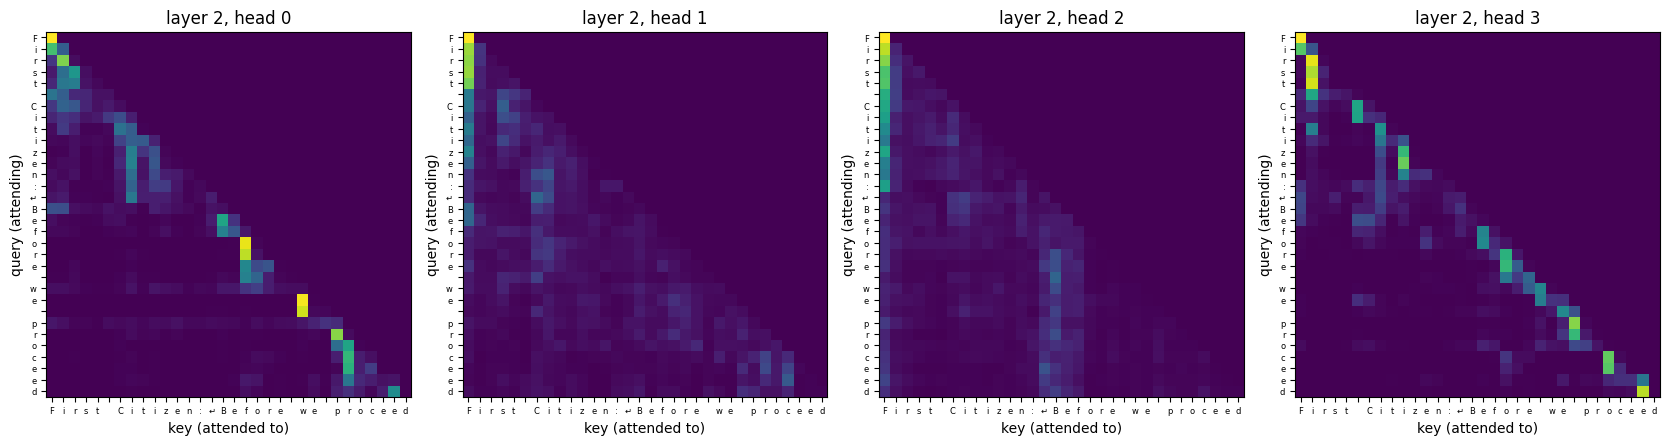

**Layer 3 · first four attention heads**

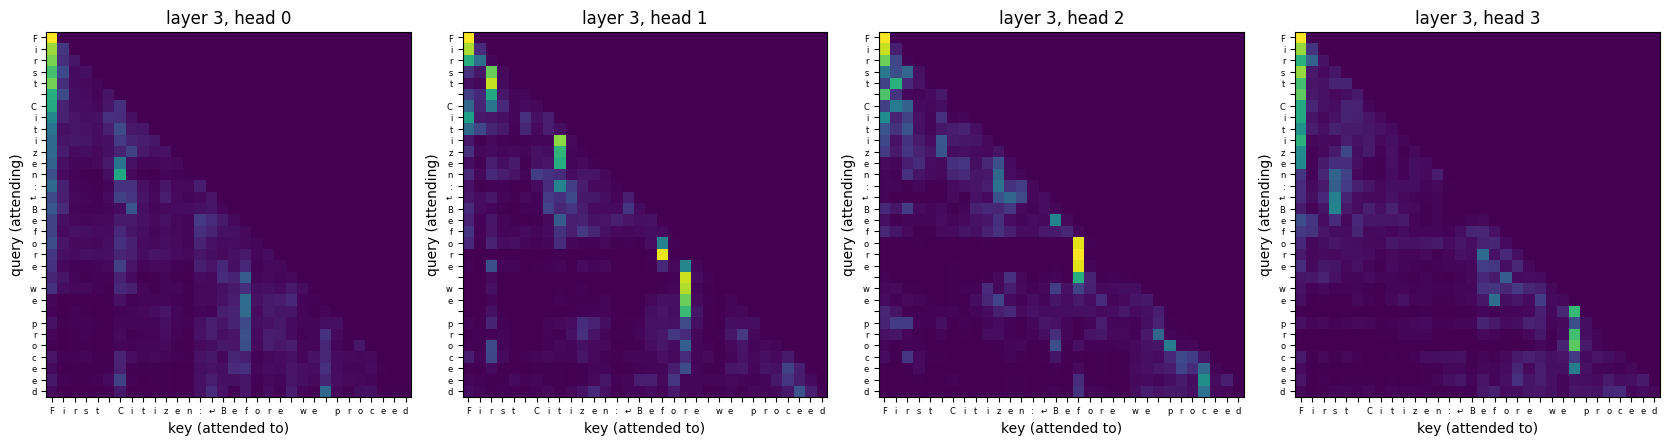

**Layer 4 · first four attention heads**

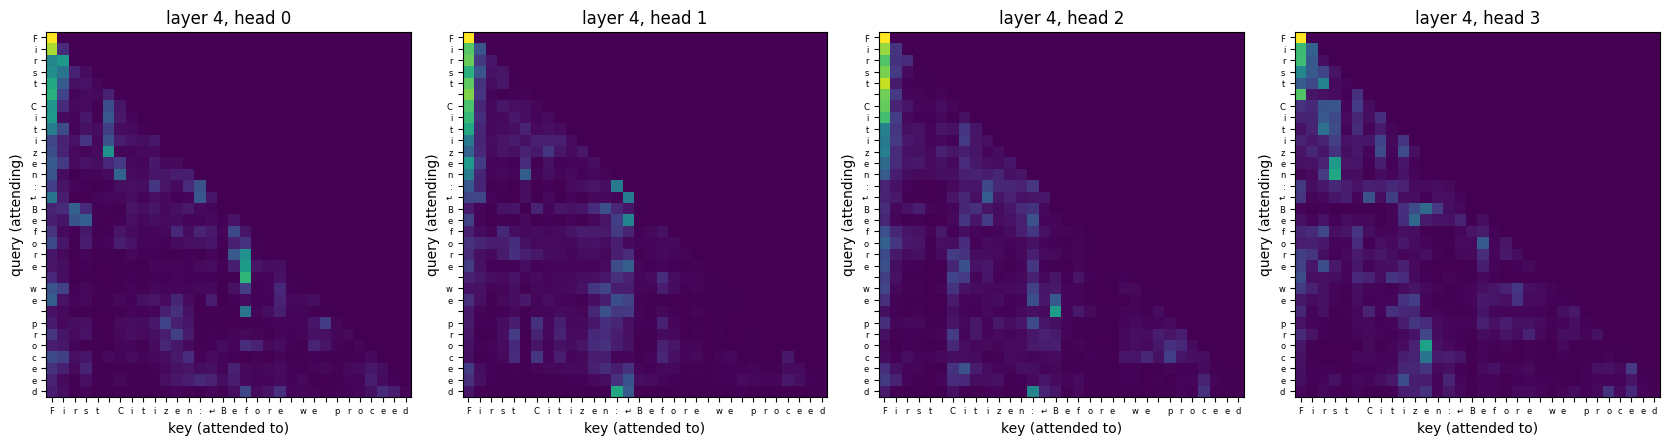

**Layer 5 · first four attention heads**

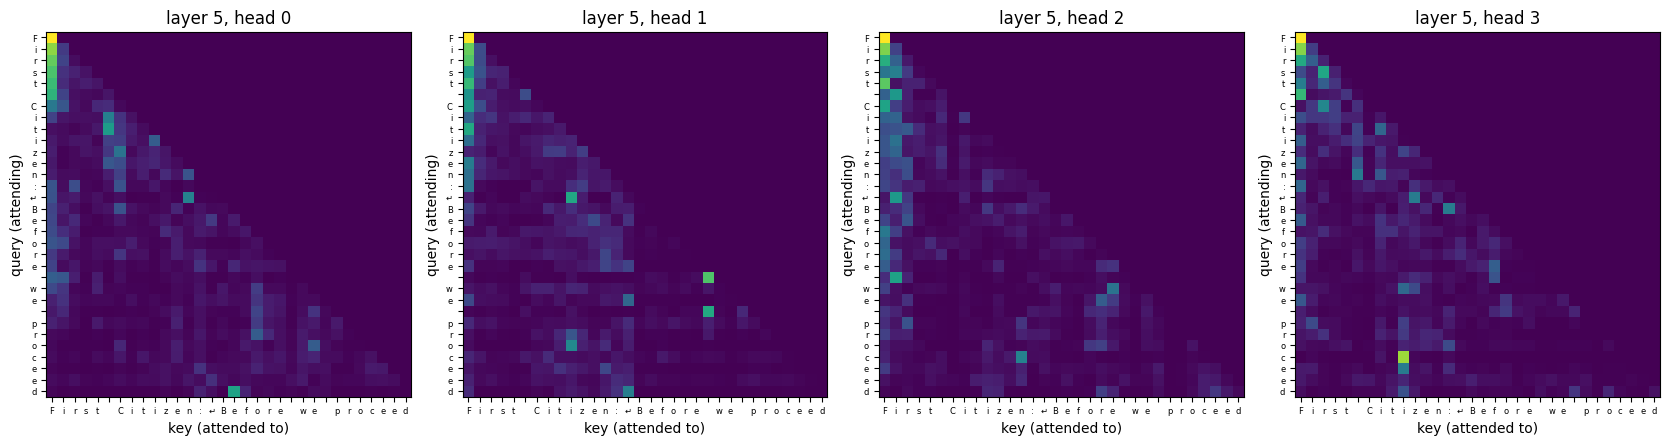

### GPT without positions: all four layers

**Layer 0 · first four attention heads**

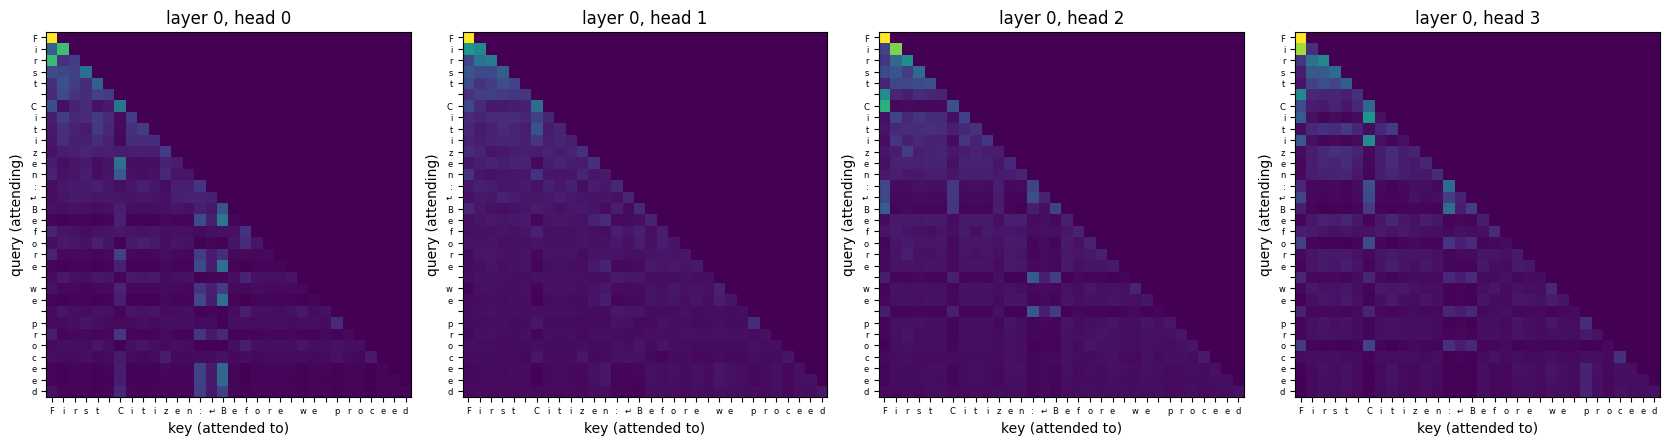

**Layer 1 · first four attention heads**

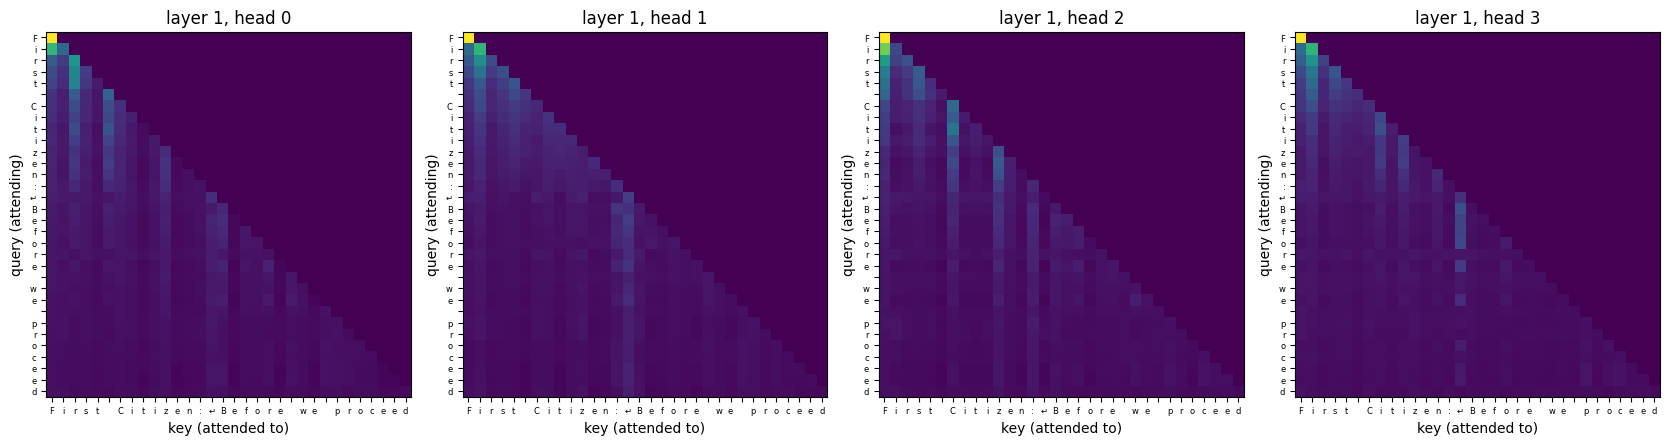

**Layer 2 · first four attention heads**

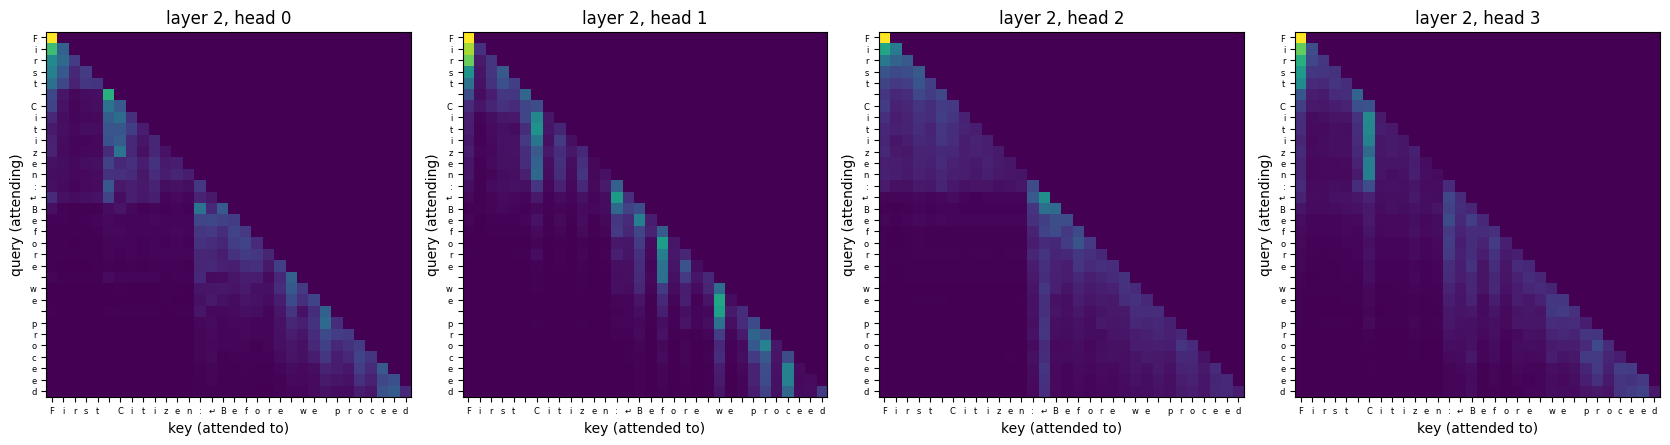

**Layer 3 · first four attention heads**

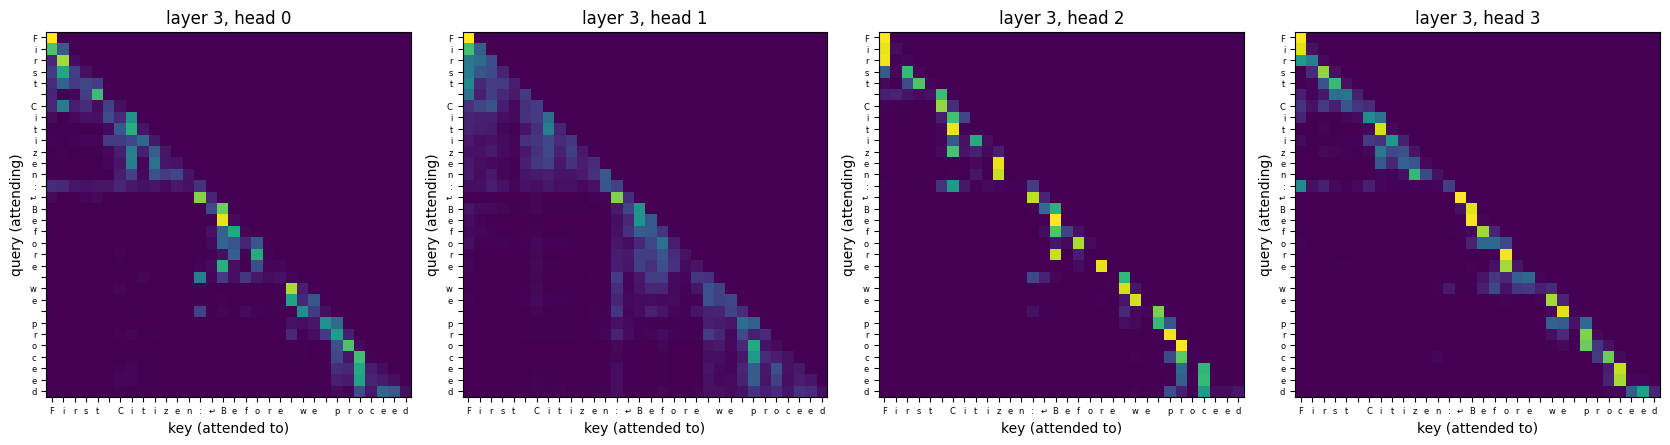

## 6. What this project demonstrates

This project connects a transparent PyTorch implementation to empirical checks:
character tokenization and shifted targets; causal multi-head attention with the
`1 / sqrt(head_size)` scale; pre-norm residual blocks; validation monitoring and
checkpoint selection; an architectural ablation; and controlled sampling comparisons.

The most useful lesson is to inspect **validation behaviour and samples together**.
Lower training loss can hide overfitting, removing a small component can hurt prediction,
and a more selective decoder can still repeat weak model predictions.

Next experiments would repeat the ablation across several seeds, compare equally sized
training budgets, select checkpoints by validation loss, and evaluate on a separate test
split. Subword tokenization or alternative position schemes would change the scope beyond
this character-level study.

<a id="implementation"></a>
## 7. One implementation for every variation

The code below consolidates the repeated notebook implementations. A configuration
object selects model size and whether to allocate positional embeddings; generation
supports temperature, top-k, and top-p for every model. The attention, feed-forward,
initialisation, and training choices follow the recorded experiments.

To execute this section, install **PyTorch, matplotlib, and Jupyter** using the accompanying
`requirements.txt` (or `%pip install torch matplotlib jupyter` in your notebook environment).
Training stays off until explicitly enabled in Section 8. No dataset download is needed
simply to read the saved results or define the models.

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F

SEED = 1337
device = ('cuda' if torch.cuda.is_available()
          else 'mps' if torch.backends.mps.is_available()
          else 'cpu')

@dataclass(frozen=True)
class ModelConfig:
    batch_size: int = 32
    block_size: int = 128
    n_embd: int = 128
    n_head: int = 4
    n_layer: int = 4
    dropout: float = 0.1
    learning_rate: float = 1e-3
    max_iters: int = 3000
    eval_interval: int = 500
    eval_iters: int = 100
    use_positions: bool = True

    def __post_init__(self):
        if min(self.batch_size, self.block_size, self.n_embd, self.n_head,
               self.n_layer, self.eval_interval, self.eval_iters) <= 0:
            raise ValueError('Model dimensions and evaluation settings must be positive')
        if self.n_embd % self.n_head:
            raise ValueError('Embedding width must be divisible by the number of heads')

CONFIGS = {
    'fast': ModelConfig(),
    'no_position': ModelConfig(use_positions=False),
    'full': ModelConfig(batch_size=64, block_size=256, n_embd=384, n_head=6,
                        n_layer=6, dropout=0.2, learning_rate=3e-4, max_iters=5000),
}
print(f'PyTorch {torch.__version__} | device: {device}')

### Corpus, vocabulary, and batches

A sorted character vocabulary gives stable token IDs. A training pair is a window of
token IDs and the same window shifted right by one character. Batches are sampled from
the chosen split and transferred to the model's device.

In [ ]:
CORPUS_URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'

def load_corpus(path=Path('data/input.txt')):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(CORPUS_URL, timeout=60) as response:
            path.write_bytes(response.read())
    text = path.read_text(encoding='utf-8')
    chars = sorted(set(text))
    if len(text) != 1_115_394 or len(chars) != 65:
        raise ValueError('Corpus differs from the recorded Tiny Shakespeare setup')
    stoi = {ch: i for i, ch in enumerate(chars)}
    data = torch.tensor([stoi[ch] for ch in text], dtype=torch.long)
    boundary = int(0.9 * len(data))
    return chars, {'train': data[:boundary], 'val': data[boundary:]}

def encode(text, chars):
    stoi = {ch: i for i, ch in enumerate(chars)}
    return [stoi[ch] for ch in text]

def decode(ids, chars):
    return ''.join(chars[i] for i in ids)

def get_batch(split, data_splits, cfg, device):
    data = data_splits[split]
    starts = torch.randint(len(data) - cfg.block_size, (cfg.batch_size,))
    x = torch.stack([data[i:i + cfg.block_size] for i in starts])
    y = torch.stack([data[i + 1:i + cfg.block_size + 1] for i in starts])
    return x.to(device), y.to(device)

### Causal attention and residual blocks

Each head projects inputs into queries, keys, and values. It computes

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}
\left(\frac{QK^\top}{\sqrt{d_k}}+M\right)V,$$

where the causal mask $M$ is $-\infty$ above the diagonal. Scaling prevents dot-product
magnitude from growing with head width. Several heads are concatenated and projected
back to the residual stream. Each pre-norm block then applies a two-layer ReLU MLP
with a fourfold hidden expansion. This follows the self-attention construction in
[Vaswani et al. (2017)](https://arxiv.org/abs/1706.03762), adapted for a causal decoder.

In [ ]:
class Head(nn.Module):
    def __init__(self, head_size, cfg):
        super().__init__()
        self.key = nn.Linear(cfg.n_embd, head_size, bias=False)
        self.query = nn.Linear(cfg.n_embd, head_size, bias=False)
        self.value = nn.Linear(cfg.n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(cfg.block_size, cfg.block_size)))
        self.dropout = nn.Dropout(cfg.dropout)
        self.keep_attn = False
        self.last_wei = None

    def forward(self, x):
        _, length, _ = x.shape
        k, q = self.key(x), self.query(x)
        weights = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
        weights = weights.masked_fill(self.tril[:length, :length] == 0, float('-inf'))
        weights = F.softmax(weights, dim=-1)
        if self.keep_attn:
            self.last_wei = weights.detach().cpu()
        return self.dropout(weights) @ self.value(x)

class MultiHeadAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.heads = nn.ModuleList([Head(cfg.n_embd // cfg.n_head, cfg)
                                    for _ in range(cfg.n_head)])
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd)
        self.dropout = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.dropout(self.proj(torch.cat([head(x) for head in self.heads], dim=-1)))

class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd), nn.ReLU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd), nn.Dropout(cfg.dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.sa = MultiHeadAttention(cfg)
        self.ffwd = FeedForward(cfg)
        self.ln1 = nn.LayerNorm(cfg.n_embd)
        self.ln2 = nn.LayerNorm(cfg.n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        return x + self.ffwd(self.ln2(x))

### The bigram and GPT models

The `use_positions` flag implements the ablation directly. When false, no position table
is allocated or added. Both models return logits and, when targets are supplied,
next-character cross-entropy. Small normal initialisation makes the GPT's initial
predictions close to uniform, with expected loss near `log(65) ≈ 4.17`.

In [ ]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size, block_size=128):
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

class GPTLanguageModel(nn.Module):
    def __init__(self, vocab_size, cfg):
        super().__init__()
        self.cfg, self.block_size = cfg, cfg.block_size
        self.token_embedding_table = nn.Embedding(vocab_size, cfg.n_embd)
        if cfg.use_positions:
            self.position_embedding_table = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.blocks = nn.Sequential(*[Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, vocab_size)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        _, length = idx.shape
        if length > self.block_size:
            raise ValueError('Input exceeds the configured context length')
        x = self.token_embedding_table(idx)
        if self.cfg.use_positions:
            x = x + self.position_embedding_table(torch.arange(length, device=idx.device))
        logits = self.lm_head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

### Sampling: temperature → top-k → top-p

At every step, crop to the model's context window, use the logits of the final position,
apply the requested filters, sample one character, and append it. The nucleus mask is
shifted by one position so the threshold-crossing character remains eligible.

In [ ]:
def filter_top_p(logits, top_p):
    if top_p is None:
        return logits
    if not 0.0 < top_p <= 1.0:
        raise ValueError('top_p must be in (0, 1], or None')
    if top_p == 1.0:
        return logits
    sorted_logits, sorted_indices = torch.sort(logits, descending=True, dim=-1)
    cumulative = F.softmax(sorted_logits, dim=-1).cumsum(dim=-1)
    remove_sorted = cumulative >= top_p
    remove_sorted[..., 1:] = remove_sorted[..., :-1].clone()
    remove_sorted[..., 0] = False
    remove = torch.zeros_like(remove_sorted).scatter(-1, sorted_indices, remove_sorted)
    return logits.masked_fill(remove, float('-inf'))

@torch.no_grad()
def generate(model, idx, max_new_tokens, temperature=1.0, top_k=None, top_p=None):
    if not math.isfinite(temperature) or temperature <= 0:
        raise ValueError('temperature must be finite and positive')
    if top_k is not None and (not isinstance(top_k, int) or top_k < 1):
        raise ValueError('top_k must be a positive integer, or None')
    if top_p is not None and not 0.0 < top_p <= 1.0:
        raise ValueError('top_p must be in (0, 1], or None')
    if idx.ndim != 2 or idx.shape[1] == 0:
        raise ValueError('Provide a nonempty batch of token sequences')
    if not isinstance(max_new_tokens, int) or max_new_tokens < 0:
        raise ValueError('max_new_tokens must be a nonnegative integer')
    was_training = model.training
    model.eval()
    try:
        for _ in range(max_new_tokens):
            logits, _ = model(idx[:, -model.block_size:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                threshold, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits = logits.masked_fill(logits < threshold[:, [-1]], float('-inf'))
            logits = filter_top_p(logits, top_p)
            idx_next = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx
    finally:
        model.train(was_training)

### Training, validation, and checkpoints

Evaluation averages 100 randomly sampled batches from each split. AdamW uses the same
default options as the original training loop. The loop evaluates before update 0 and
after each 500 updates, including the final update. It keeps the final model in memory
to match the recorded samples and can save both **best** and **last** checkpoints.
Each new checkpoint includes the vocabulary and configuration needed to reload it.

In [ ]:
@torch.no_grad()
def estimate_loss(model, data_splits, cfg, device):
    was_training = model.training
    model.eval()
    result = {}
    try:
        for split in ('train', 'val'):
            losses = torch.zeros(cfg.eval_iters)
            for i in range(cfg.eval_iters):
                x, y = get_batch(split, data_splits, cfg, device)
                _, loss = model(x, y)
                losses[i] = loss.item()
            result[split] = losses.mean().item()
        return result
    finally:
        model.train(was_training)

def save_checkpoint(path, model, cfg, chars, step, val_loss):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({'config': asdict(cfg), 'chars': chars,
                'model_kind': 'gpt' if isinstance(model, GPTLanguageModel) else 'bigram',
                'state_dict': model.state_dict(), 'step': step, 'val_loss': val_loss}, path)

def load_checkpoint(path, device=device):
    record = torch.load(path, map_location=device, weights_only=True)
    cfg, chars = ModelConfig(**record['config']), record['chars']
    if record['model_kind'] == 'gpt':
        model = GPTLanguageModel(len(chars), cfg)
    else:
        model = BigramLanguageModel(len(chars), cfg.block_size)
    model = model.to(device)
    model.load_state_dict(record['state_dict'])
    model.eval()
    return model, cfg, chars

def train(model, data_splits, cfg, device, chars, *, learning_rate=None, checkpoint_dir=None):
    lr = cfg.learning_rate if learning_rate is None else learning_rate
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history, best_val = [], float('inf')
    started = time.time()
    model.train()
    for step in range(cfg.max_iters + 1):
        if step % cfg.eval_interval == 0 or step == cfg.max_iters:
            losses = estimate_loss(model, data_splits, cfg, device)
            history.append((step, losses['train'], losses['val']))
            print(f"step {step:5d} | train loss {losses['train']:.4f} | "
                  f"val loss {losses['val']:.4f} | {time.time() - started:6.1f}s")
            if losses['val'] < best_val:
                best_val = losses['val']
                if checkpoint_dir is not None:
                    save_checkpoint(Path(checkpoint_dir) / 'best.pt', model, cfg, chars,
                                    step, losses['val'])
        if step == cfg.max_iters:
            if checkpoint_dir is not None:
                save_checkpoint(Path(checkpoint_dir) / 'last.pt', model, cfg, chars,
                                step, losses['val'])
            break
        x, y = get_batch('train', data_splits, cfg, device)
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    return history

### Inspect a trained model's attention

This helper records the selected layer's attention weights without dropout, labels query
and key positions with characters, and restores the model's previous mode afterwards.

In [ ]:
@torch.no_grad()
def show_attention(model, chars, prompt, layer=0, max_heads=4):
    model_device = next(model.parameters()).device
    ids = torch.tensor([encode(prompt, chars)], dtype=torch.long, device=model_device)
    ids = ids[:, -model.block_size:]
    if ids.shape[1] == 0:
        raise ValueError('Provide a nonempty attention prompt')
    heads = model.blocks[layer].sa.heads
    was_training = model.training
    model.eval()
    try:
        for head in heads:
            head.keep_attn = True
        model(ids)
        count = min(max_heads, len(heads))
        labels = [ch if ch != '\n' else '↵' for ch in decode(ids[0].tolist(), chars)]
        fig, axes = plt.subplots(1, count, figsize=(4.2 * count, 4.4), squeeze=False)
        for i, ax in enumerate(axes[0]):
            ax.imshow(heads[i].last_wei[0].numpy(), cmap='viridis')
            ax.set_title(f'layer {layer}, head {i}')
            ax.set_xticks(range(len(labels)), labels, fontsize=6)
            ax.set_yticks(range(len(labels)), labels, fontsize=6)
            ax.set(xlabel='key (attended to)', ylabel='query (attending)')
        plt.tight_layout()
        plt.show()
    finally:
        for head in heads:
            head.keep_attn, head.last_wei = False, None
        model.train(was_training)

<a id="rerun"></a>
## 8. Run your own experiments

Leave the defaults below to keep all saved results and skip training. To train a variant,
add its name to `RUNS_TO_TRAIN`. Use `['fast', 'no_position']` for the ablation, or `['full']`
for the larger model. The trained fast model can also run every sampling strategy.

Dataset download happens only when a training switch is enabled. The full preset is best
run on an accelerator; the saved CUDA timings are historical observations, not runtime
promises for another machine. New results may differ across hardware and PyTorch versions.

In [ ]:
RUNS_TO_TRAIN = []  # Available: 'fast', 'no_position', 'full'
TRAIN_BIGRAM = False
SAVE_CHECKPOINTS = False

live_runs = {}
if TRAIN_BIGRAM or RUNS_TO_TRAIN:
    chars, data_splits = load_corpus()
    run_stamp = time.strftime('%Y%m%d-%H%M%S')

    if TRAIN_BIGRAM:
        cfg = CONFIGS['fast']
        torch.manual_seed(SEED)
        model = BigramLanguageModel(len(chars), cfg.block_size).to(device)
        checkpoint_dir = Path('checkpoints') / run_stamp / 'bigram' if SAVE_CHECKPOINTS else None
        history = train(model, data_splits, cfg, device, chars,
                        learning_rate=1e-2, checkpoint_dir=checkpoint_dir)
        live_runs['bigram'] = {'model': model, 'history': history, 'chars': chars}

    for name in RUNS_TO_TRAIN:
        cfg = CONFIGS[name]
        torch.manual_seed(SEED)
        model = GPTLanguageModel(len(chars), cfg).to(device)
        print(f"\n{name}: {sum(p.numel() for p in model.parameters()):,} parameters")
        x, y = get_batch('train', data_splits, cfg, device)
        _, initial_loss = model(x, y)
        print(f'Initial loss: {initial_loss.item():.3f} | uniform: {math.log(len(chars)):.3f}')
        # The recorded fast runs reset once more immediately before training.
        if name != 'full':
            torch.manual_seed(SEED)
        checkpoint_dir = Path('checkpoints') / run_stamp / name if SAVE_CHECKPOINTS else None
        history = train(model, data_splits, cfg, device, chars, checkpoint_dir=checkpoint_dir)
        live_runs[name] = {'model': model, 'history': history, 'chars': chars}
else:
    print('Training skipped. The recorded results above remain available.')

The consolidated runner follows the same optimisation settings; exact historical samples
also depend on the original sequence of random operations. The archived outputs are kept
as the record of those runs. New histories are stored separately in `live_runs`.

### Compare decoding after training (or loading) a model

The following cell runs only when `live_runs` contains a fast GPT. To use a checkpoint
created above without retraining:

```python
model, cfg, chars = load_checkpoint('checkpoints/<run>/fast/best.pt')
live_runs['fast'] = {'model': model, 'chars': chars}
```

The new checkpoint format includes configuration and vocabulary. The original standalone
weight files are not bundled with this portfolio; the recorded samples need no weight file.

In [ ]:
SAMPLING_SETTINGS = [
    ('Temperature 0.5', 0.5, None, None),
    ('Standard sampling', 1.0, None, None),
    ('Temperature 1.5', 1.5, None, None),
    ('Top-k = 10', 1.0, 10, None),
    ('Top-p = 0.80', 1.0, None, 0.80),
    ('Top-p = 0.90', 1.0, None, 0.90),
    ('Top-p = 0.95', 1.0, None, 0.95),
]
if 'fast' in live_runs:
    model, chars = live_runs['fast']['model'], live_runs['fast']['chars']
    model_device = next(model.parameters()).device
    prompt = torch.tensor([encode('ROMEO:\n', chars)], dtype=torch.long, device=model_device)
    for label, temperature, top_k, top_p in SAMPLING_SETTINGS:
        torch.manual_seed(SEED)
        output = generate(model, prompt, 250, temperature, top_k, top_p)
        print(f'\n--- {label} ---\n{decode(output[0].tolist(), chars)}')

# To inspect any trained GPT, for example:
# record = live_runs['fast']
# show_attention(record['model'], record['chars'], 'First Citizen:\nBefore we proceed', layer=0)